# Week 4: Data Exploration and Transformations
**Course / Assignment:** Data Exploration & Transformations  
**Dataset:** Medical Cost Personal Datasets (Kaggle)  
**Dataset Source Link:** [https://www.kaggle.com/datasets/mirichoi0218/insurance](https://www.kaggle.com/datasets/mirichoi0218/insurance)  
**Author / Contributor:** Student Academic Submission  
**Documentation Style:** American Psychological Association (APA) 7th Edition  

---

## 1. Introduction and Objectives
Exploratory Data Analysis (EDA) is a foundational process in data science designed to inspect data characteristics, diagnose anomalies such as missingness and duplicates, detect outliers, and apply mathematical transformations to stabilize distributions. 

This notebook presents an end-to-end data exploration, cleaning, transformation, and visualization pipeline using the **Medical Cost Personal Datasets** obtained from Kaggle. The objective is to evaluate how individual demographic and health behaviors—specifically Body Mass Index (BMI) and smoking habits—influence annual medical expenditures.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14,
    "figure.dpi": 150
})

print("Libraries imported successfully.")


Libraries imported successfully.


---
## 2. Dataset Loading and Initial Inspection
We load the raw dataset (`raw_insurance.csv`), which records 1,338 individual beneficiaries across seven clinical and demographic variables:
- `age`: Primary beneficiary age (years).
- `sex`: Insurance contractor gender (`female`, `male`).
- `bmi`: Body Mass Index ($kg/m^2$).
- `children`: Number of dependent children/dependents covered.
- `smoker`: Smoking status (`yes`, `no`).
- `region`: Beneficiary residential area in the US (`northeast`, `southeast`, `southwest`, `northwest`).
- `charges`: Individual medical costs billed by health insurance ($USD).


In [2]:
raw_path = os.path.join("..", "data", "raw_insurance.csv")
if not os.path.exists(raw_path):
    raw_path = os.path.join("data", "raw_insurance.csv")

df = pd.read_csv(raw_path)
print(f"Raw Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Raw Dataset Dimensions: 1338 rows, 7 columns


   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


---
## 3. Data Cleaning: Missing Values, Duplicates, and Data Types
Rigorous data quality audits are performed to examine missingness, duplicated entries, and data type alignment.


In [3]:
# 1. Missing Values
print("Missing values per column:")
print(df.isnull().sum())

# 2. Duplicate Detection
dup_count = df.duplicated().sum()
print(f"\nNumber of duplicate records detected: {dup_count}")
if dup_count > 0:
    print("\nDuplicate observations:")
    display(df[df.duplicated(keep=False)])

# 3. Duplicate Removal
df_clean = df.drop_duplicates().copy()
print(f"\nShape after deduplication: {df_clean.shape}")

# 4. Data Type Corrections
categorical_cols = ['sex', 'smoker', 'region']
for col in categorical_cols:
    df_clean[col] = df_clean[col].astype('category')
df_clean['age'] = df_clean['age'].astype(int)
df_clean['children'] = df_clean['children'].astype(int)

print("\nVerified Data Types:")
print(df_clean.dtypes)


Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Number of duplicate records detected: 1

Duplicate observations:
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631

Shape after deduplication: (1337, 7)

Verified Data Types:
age            int32
sex         category
bmi          float64
children       int32
smoker      category
region      category
charges      float64
dtype: object


---
## 4. Outlier Detection and Analysis (IQR Method)
Using John Tukey’s Interquartile Range (IQR) rule, observation $x$ is flagged as an outlier if $x < Q_1 - 1.5 \times \text{IQR}$ or $x > Q_3 + 1.5 \times \text{IQR}$, where $\text{IQR} = Q_3 - Q_1$.


In [4]:
for col in ['bmi', 'charges']:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
    print(f"Feature '{col}': Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
    print(f"  Valid Range: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"  Outliers Flagged: {len(outliers)} ({len(outliers)/len(df_clean)*100:.2f}%)\n")


Feature 'bmi': Q1=26.29, Q3=34.70, IQR=8.41
  Valid Range: [13.67, 47.32]
  Outliers Flagged: 9 (0.67%)

Feature 'charges': Q1=4746.34, Q3=16657.72, IQR=11911.37
  Valid Range: [-13120.72, 34524.78]
  Outliers Flagged: 139 (10.40%)



---
## 5. Data Transformations and Feature Engineering
Two primary transformations are executed:
1. **Natural Log Transformation ($\ln(	ext{charges})$):** Addressing extreme positive skewness in medical charges.
2. **Clinical BMI Categorization:** Grouping continuous BMI values according to World Health Organization (WHO) clinical tiers:
   - Underweight ($< 18.5$)
   - Normal weight ($18.5 - 24.9$)
   - Overweight ($25.0 - 29.9$)
   - Obese ($\ge 30.0$)


In [5]:
# 1. Log Transformation
raw_skew = df_clean['charges'].skew()
df_clean['log_charges'] = np.log(df_clean['charges'])
log_skew = df_clean['log_charges'].skew()

print(f"Original charges skewness: {raw_skew:.4f}")
print(f"Log-transformed charges skewness: {log_skew:.4f}")

# 2. BMI Clinical Categories
bmi_bins = [0, 18.5, 24.9, 29.9, 100]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
df_clean['bmi_category'] = pd.cut(df_clean['bmi'], bins=bmi_bins, labels=bmi_labels, right=True)

# 3. Binary Smoker Encoding
df_clean['smoker_code'] = df_clean['smoker'].map({'no': 0, 'yes': 1}).astype(int)

# Export cleaned dataset
clean_path = os.path.join("..", "data", "cleaned_insurance.csv")
if not os.path.exists(os.path.dirname(clean_path)):
    clean_path = os.path.join("data", "cleaned_insurance.csv")
df_clean.to_csv(clean_path, index=False)
print(f"Cleaned dataset saved successfully to {clean_path}")


Original charges skewness: 1.5154
Log-transformed charges skewness: -0.0898
Cleaned dataset saved successfully to week4/data/cleaned_insurance.csv


---
## 6. Visualization 1: Distribution of Medical Charges (Histogram & Transformation)
The histogram below depicts the distribution of annual medical expenditures before and after logarithmic transformation, showing the sample mean and median.


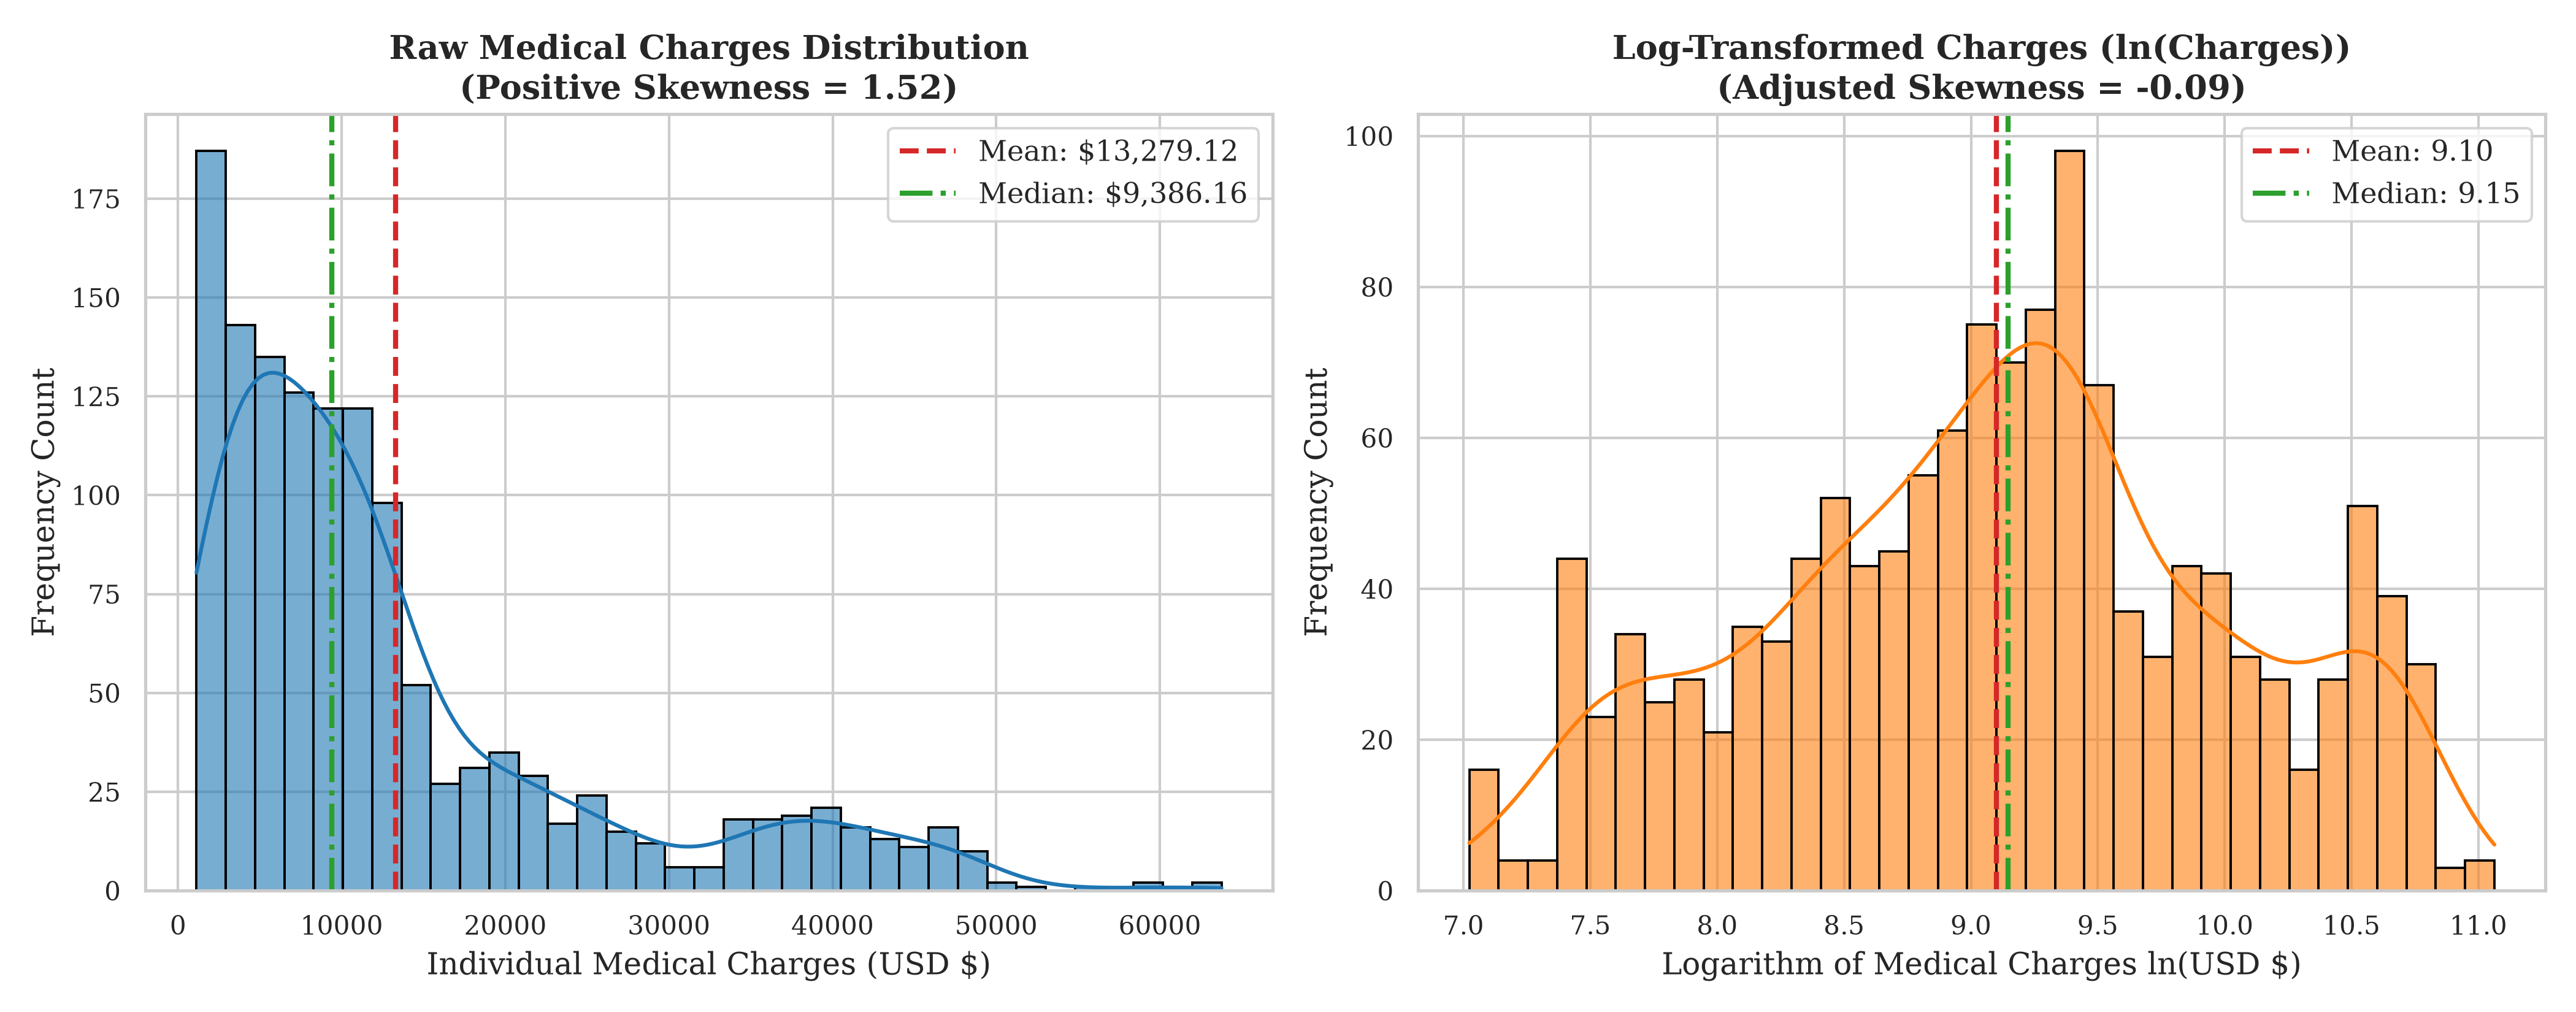

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Raw Charges Distribution
mean_charges = df_clean['charges'].mean()
median_charges = df_clean['charges'].median()
sns.histplot(df_clean['charges'], kde=True, bins=35, color="#1f77b4", edgecolor="black", alpha=0.6, ax=axes[0])
axes[0].axvline(mean_charges, color="#d62728", linestyle="--", linewidth=2, label=f"Mean: ${mean_charges:,.2f}")
axes[0].axvline(median_charges, color="#2ca02c", linestyle="-.", linewidth=2, label=f"Median: ${median_charges:,.2f}")
axes[0].set_title(f"Raw Medical Charges Distribution\n(Positive Skewness = {raw_skew:.2f})", fontweight="bold")
axes[0].set_xlabel("Annual Medical Charges (USD $)")
axes[0].set_ylabel("Frequency Count")
axes[0].legend(loc="upper right", frameon=True)

# Log-Transformed Charges Distribution
mean_log = df_clean['log_charges'].mean()
median_log = df_clean['log_charges'].median()
sns.histplot(df_clean['log_charges'], kde=True, bins=35, color="#ff7f0e", edgecolor="black", alpha=0.6, ax=axes[1])
axes[1].axvline(mean_log, color="#d62728", linestyle="--", linewidth=2, label=f"Mean: {mean_log:.2f}")
axes[1].axvline(median_log, color="#2ca02c", linestyle="-.", linewidth=2, label=f"Median: {median_log:.2f}")
axes[1].set_title(f"Log-Transformed Charges (ln(Charges))\n(Adjusted Skewness = {log_skew:.2f})", fontweight="bold")
axes[1].set_xlabel("Logarithm of Medical Charges ln(USD $)")
axes[1].set_ylabel("Frequency Count")
axes[1].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


---
## 7. Visualization 2: Relationship Between BMI and Medical Charges by Smoking Status (Scatter Plot)
The scatter plot demonstrates the interaction between Body Mass Index (BMI) and annual medical charges, stratified by smoking status.


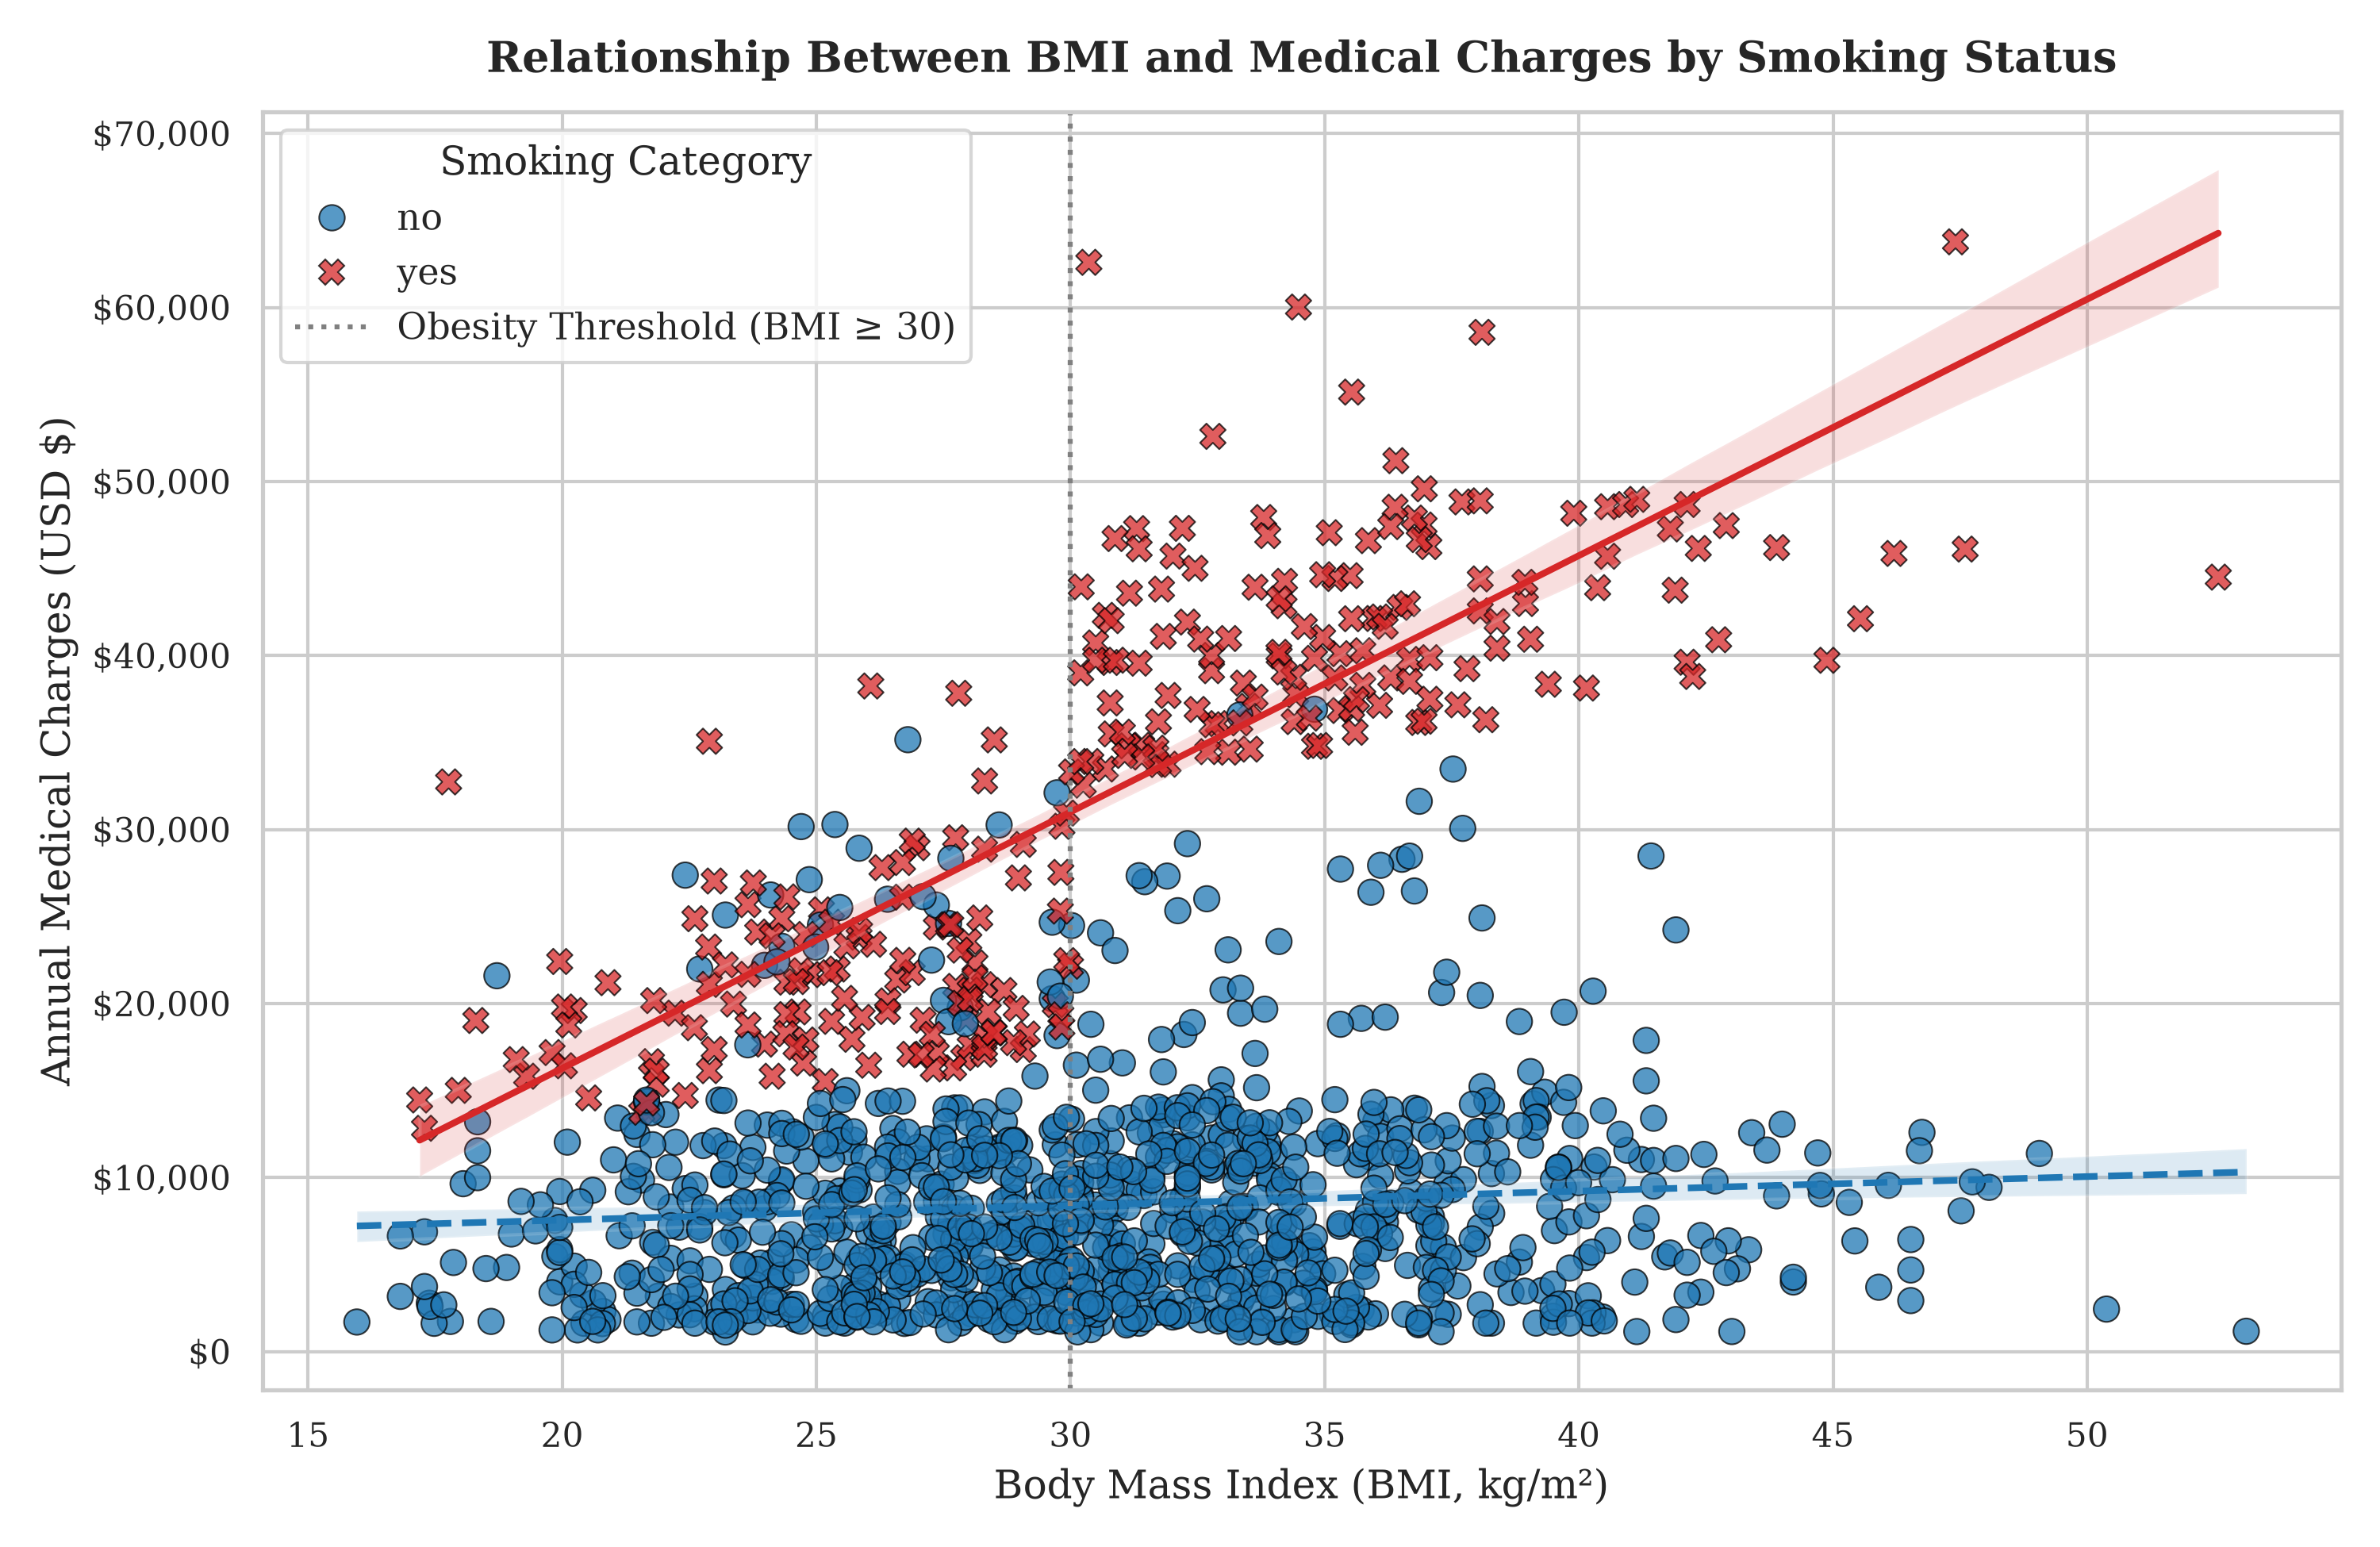

In [7]:
fig, ax = plt.subplots(figsize=(10, 6.5))
palette = {"yes": "#d62728", "no": "#1f77b4"}

sns.scatterplot(
    data=df_clean,
    x="bmi",
    y="charges",
    hue="smoker",
    style="smoker",
    palette=palette,
    alpha=0.75,
    s=60,
    edgecolor="black",
    linewidth=0.5,
    ax=ax
)

sns.regplot(
    data=df_clean[df_clean['smoker'] == 'no'],
    x="bmi",
    y="charges",
    scatter=False,
    ax=ax,
    color="#1f77b4",
    line_kws={"linewidth": 2, "linestyle": "--", "label": "Non-Smoker Trend"}
)
sns.regplot(
    data=df_clean[df_clean['smoker'] == 'yes'],
    x="bmi",
    y="charges",
    scatter=False,
    ax=ax,
    color="#d62728",
    line_kws={"linewidth": 2, "linestyle": "-", "label": "Smoker Trend"}
)

ax.axvline(30.0, color="gray", linestyle=":", linewidth=1.5, label="Obesity Threshold (BMI ≥ 30)")
ax.set_title("Relationship Between BMI and Medical Charges by Smoking Status", fontweight="bold", pad=12)
ax.set_xlabel("Body Mass Index (BMI, kg/m²)")
ax.set_ylabel("Annual Medical Charges (USD $)")
ax.yaxis.set_major_formatter('${x:,.0f}')

handles, labels = ax.get_legend_handles_labels()
ax.legend(loc="upper left", frameon=True, title="Smoking Category")

plt.tight_layout()
plt.show()


---
## 8. Summary Statistics and Analytical Insights
We evaluate the central tendencies and subgroup breakdowns across smoking and BMI categories.


In [8]:
subgroup_summary = df_clean.groupby(['smoker', 'bmi_category'], observed=True)['charges'].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Std='std',
    Min='min',
    Max='max'
).reset_index()

print("Subgroup Charges Summary (Smoking Status & BMI Category):")
subgroup_summary


Subgroup Charges Summary (Smoking Status & BMI Category):


  smoker  bmi_category  Count          Mean        Median           Std          Min          Max
0     no   Underweight     15   8657.620667   6686.431300   7075.761503  1621.340200  27724.28875
1     no        Normal    196   7929.623193   7050.602000   5721.408711  1121.873900  32108.66352
2     no    Overweight    307   8344.696144   7372.093000   5777.674996  1252.407000  35160.13457
3     no         Obese    545   8842.668383   8023.135450   6164.717140  1135.940700  36910.60803
4    yes   Underweight      5  18809.824980  19719.694700   4766.721245 12829.455100  25382.29700
5    yes        Normal     40  19942.223561  20235.155450   4399.851993 13770.097900  28101.33980
6    yes    Overweight     78  22495.874163  21782.358200   4818.043513 15359.104500  38245.59324
7    yes         Obese    151  41692.624701  40974.164900   5796.883906 32548.340500  63770.42801


---
## 9. References (APA 7th Edition)

- Choi, M. (2018). *Medical Cost Personal Datasets* [Data set]. Kaggle. https://www.kaggle.com/datasets/mirichoi0218/insurance
- Lantz, B. (2019). *Machine learning with R: Expert techniques for predictive modeling to solve advanced problems* (3rd ed.). Packt Publishing.
- Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley Publishing Company.
- World Health Organization. (2020). *Obesity and overweight*. World Health Organization. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight
